# JSON LabelMe to GeoJSON

In [2]:
import json
import rasterio
import os
import glob
from pathlib import Path

def labelme_to_geojson(input_json_path, input_tif_path, output_geojson_path):
    # Read LabelMe JSON file
    with open(input_json_path, 'r') as f:
        labelme_data = json.load(f)
    
    # Read georeference information from TIF
    with rasterio.open(input_tif_path) as src:
        # Get the transformation matrix
        transform = src.transform
        # Get the CRS
        crs = src.crs.to_string()
    
    # Initialize GeoJSON structure
    geojson = {
        "type": "FeatureCollection",
        "name": Path(input_json_path).stem,  # Use filename as name
        "crs": {
            "type": "name",
            "properties": {
                "name": f"urn:ogc:def:crs:EPSG::{src.crs.to_epsg()}"
            }
        },
        "features": []
    }

    # Convert each polygon annotation to GeoJSON feature
    for shape in labelme_data['shapes']:
        if shape['shape_type'] == 'polygon':

            confidence_score = shape["score"]

            # Convert pixel coordinates to geographic coordinates
            coords = []
            for point in shape['points']:
                # Convert from pixel coordinates to geographic coordinates using the transform
                geo_x, geo_y = transform * (point[0], point[1])
                coords.append([geo_x, geo_y])
            
            # Close the polygon by adding the first point at the end
            coords.append(coords[0])
            
            # Create GeoJSON feature
            feature = {
                "type": "Feature",
                "properties": {
                    "Confidence_score": confidence_score
                    #"label": shape['label']
                },
                "geometry": {
                    "type": "Polygon",
                    "coordinates": [coords]
                }
            }
            
            geojson['features'].append(feature)

    # Write GeoJSON file
    with open(output_geojson_path, 'w') as f:
        json.dump(geojson, f, indent=2)

def process_directory(input_json_dir, input_tif_dir, output_dir):
    """
    Memproses semua file JSON LabelMe dalam direktori, mencocokkannya dengan 
    file TIF yang sesuai dari direktori lain, dan mengonversinya ke GeoJSON.
    """
    # Buat direktori output jika belum ada
    os.makedirs(output_dir, exist_ok=True)
    
    # Dapatkan semua file JSON di direktori input
    json_files = glob.glob(os.path.join(input_json_dir, "*.json"))
    
    if not json_files:
        print(f"Warning: Tidak ada file .json yang ditemukan di {input_json_dir}")
        return

    print(f"Menemukan {len(json_files)} file JSON untuk diproses...")
    
    # Proses setiap file
    for json_file in json_files:
        # Dapatkan nama file dasar (misal: 'gambar_01')
        base_name = Path(json_file).stem
        
        # === PERBAIKAN DI SINI ===
        # Bangun path file TIF yang sesuai menggunakan input_tif_dir
        tif_file = os.path.join(input_tif_dir, base_name + '.tif')
        
        # Lewati jika file TIF yang cocok tidak ada
        if not os.path.exists(tif_file):
            print(f"Warning: Tidak ada TIF file yang cocok di {tif_file} untuk {Path(json_file).name}")
            continue
        
        # Bangun nama file output GeoJSON
        output_file = os.path.join(output_dir, base_name + '.geojson')
        
        try:
            print(f"Processing {Path(json_file).name}...")
            # Panggil fungsi konversi Anda
            labelme_to_geojson(json_file, tif_file, output_file)
            print(f"Successfully created {Path(output_file).name}")
        except Exception as e:
            print(f"Error processing {Path(json_file).name}: {str(e)}")

In [3]:
# Example usage
input_json_dir  = "./sample/tiles"
input_tif_dir   = "./sample/tiles"
output_dir      = "./sample/tiles/geojson"

process_directory(input_json_dir, input_tif_dir, output_dir)

Menemukan 167 file JSON untuk diproses...
Processing tile_0_0.json...
Successfully created tile_0_0.geojson
Processing tile_0_1.json...
Successfully created tile_0_1.geojson
Processing tile_0_10.json...
Successfully created tile_0_10.geojson
Processing tile_0_11.json...
Successfully created tile_0_11.geojson
Processing tile_0_12.json...
Successfully created tile_0_12.geojson
Processing tile_0_2.json...
Successfully created tile_0_2.geojson
Processing tile_0_3.json...
Successfully created tile_0_3.geojson
Processing tile_0_4.json...
Successfully created tile_0_4.geojson
Processing tile_0_5.json...
Successfully created tile_0_5.geojson
Processing tile_0_6.json...
Successfully created tile_0_6.geojson
Processing tile_0_7.json...
Successfully created tile_0_7.geojson
Processing tile_0_8.json...
Successfully created tile_0_8.geojson
Processing tile_0_9.json...
Successfully created tile_0_9.geojson
Processing tile_10_0.json...
Successfully created tile_10_0.geojson
Processing tile_10_1.json.

# Divide-and-Conquer Geometric NMS (DC-GNMS)

motivated by Ball. et al., 2023

### Fix Code DC-GNMS for Publish with Self-Training

In [ ]:
import geopandas as gpd
import pandas as pd
import glob
import os
from shapely.geometry import box

# --- 1. PENGATURAN DIREKTORI & PARAMETER ---
INPUT_GEOJSON_DIR = "D:/RESEARCH/SK3_UrbanTreeDT/self_training/tree_test_evaluation/tree_test/geojson/"
OUTPUT_FINAL_GPKG = "D:/RESEARCH/SK3_UrbanTreeDT/self_training/tree_test_evaluation/tree_test/crown_tree_test_bandung_dcgnms.gpkg"

BOX_FILTER_SHIFT = 1.0
SCORE_COLUMN = "Confidence_score" 
OVERLAP_THRESHOLD = 0.5  # Batas overlap (50%) menggunakan metode IoA/IoMin
CROSS_ZONE_THRESHOLD = 0.15  # Toleransi overlap 15%. Ubah sesuai kebutuhan.

# --- 2. FUNGSI HELPER & PRAPROSES ---
def get_crs_from_file(files):
    if not files: return None
    try:
        gdf = gpd.read_file(files[0])
        return gdf.crs
    except Exception as e:
        print(f"Warning: Gagal membaca CRS: {e}")
        return None

def create_center_box(gdf: gpd.GeoDataFrame, shift: float):
    bounds = gdf.total_bounds
    buffered_box = box(bounds[0] + shift, bounds[1] + shift, bounds[2] - shift, bounds[3] - shift)
    return gpd.GeoDataFrame(geometry=[buffered_box], crs=gdf.crs)

def preprocess_tile(gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    """Praproses: buffer(0) untuk perbaikan topologi, buang invalid/kosong, filter luasan."""
    gdf["geometry"] = gdf.geometry.buffer(0)
    gdf = gdf[gdf.geometry.is_valid & ~gdf.geometry.is_empty]
    gdf = gdf[gdf.geometry.area >= 2.0]
    return gdf

# --- 3. FUNGSI NMS DENGAN IOMIN (ANTI-POLIGON KECIL LOLOS) ---
def apply_nms_by_score(gdf: gpd.GeoDataFrame, score_col: str, overlap_thresh: float, desc="NMS") -> gpd.GeoDataFrame:
    if gdf.empty: return gdf
    
    if score_col not in gdf.columns:
        print(f"  [Warning] Kolom '{score_col}' tidak ditemukan! Melewati {desc}.")
        return gdf

    # Pilih berdasarkan skor tertinggi
    gdf = gdf.sort_values(by=score_col, ascending=False).reset_index(drop=True)
    
    sindex = gdf.sindex
    suppressed_indices = set()
    keep_indices = []

    for i, row in gdf.iterrows():
        if i in suppressed_indices:
            continue
            
        keep_indices.append(i)
        geom_A = row.geometry
        area_A = geom_A.area
        
        possible_matches = list(sindex.query(geom_A, predicate='intersects'))
        
        for j in possible_matches:
            if j <= i or j in suppressed_indices: 
                continue
                
            geom_B = gdf.loc[j].geometry
            area_B = geom_B.area
            
            intersection_area = geom_A.intersection(geom_B).area
            if intersection_area == 0:
                continue
            
            # Bandingkan luas irisan dengan luas poligon terkecil (IoMin)
            min_area = min(area_A, area_B)
            overlap_ratio = intersection_area / min_area
            
            if overlap_ratio > overlap_thresh:
                suppressed_indices.add(j)

    return gdf.loc[keep_indices].copy()

# --- 4. FUNGSI CROSS-ZONE FILTER ---
def cross_zone_filter(gdf_edge: gpd.GeoDataFrame, gdf_center: gpd.GeoDataFrame, threshold: float) -> gpd.GeoDataFrame:
    """
    Menghapus poligon Edge jika beririsan dengan Center melebihi batas toleransi area (IoA).
    """
    if gdf_edge.empty or gdf_center.empty:
        return gdf_edge

    print(f"\n  [Cross-Zone] Membandingkan {len(gdf_edge)} EDGE vs {len(gdf_center)} CENTER (Toleransi Overlap: {threshold*100}%)...")
    
    # 1. Spatial Join (Fase Cepat): Cari semua Edge yang menyentuh Center
    joined = gpd.sjoin(gdf_edge, gdf_center, how="inner", predicate="intersects")
    
    if joined.empty:
        return gdf_edge

    indices_to_delete = set()
    
    # 2. Evaluasi Area (Fase Presisi): Cek seberapa besar tumpang tindihnya
    for edge_idx, row in joined.iterrows():
        if edge_idx in indices_to_delete:
            continue
            
        center_idx = row['index_right']
        
        try:
            edge_geom = gdf_edge.geometry.loc[edge_idx]
            center_geom = gdf_center.geometry.loc[center_idx]
            
            # Hitung luas area yang tumpang tindih
            intersection_area = edge_geom.intersection(center_geom).area
            
            if intersection_area == 0:
                continue
                
            # Hitung persentase tumpang tindih relatif terhadap poligon Edge
            ioa_edge = intersection_area / edge_geom.area
            
            # Jika edge 'termakan' oleh center lebih besar dari batas toleransi, anggap sebagai artefak potongan
            if ioa_edge > threshold:
                indices_to_delete.add(edge_idx)
        except Exception:
            pass
            
    print(f"  [Cross-Zone] Menghapus {len(indices_to_delete)} fragmen EDGE yang tumpang tindih > {threshold*100}% dengan CENTER...")
    
    # Buang poligon yang melebihi threshold
    gdf_edge_survivors = gdf_edge.drop(index=list(indices_to_delete)).reset_index(drop=True)
    return gdf_edge_survivors

# --- 5. FUNGSI UTAMA ---
def dc_gnms(geojson_dir, out_final, shift):
    files = glob.glob(os.path.join(geojson_dir, "*.geojson"))
    if not files:
        print(f"Error: Tidak ada file .geojson ditemukan di {geojson_dir}")
        return

    print(f"Menemukan {len(files)} file GeoJSON. Memulai proses DIVIDE...\n")
    target_crs = get_crs_from_file(files)
    
    center_polygons_list = []
    edge_polygons_list = []

    # --- TAHAP 1: DIVIDE & INTRA-NMS ---
    for idx, file in enumerate(files, start=1):
        if idx % 100 == 0:
            print(f"  ...memproses file {idx} dari {len(files)}: {os.path.basename(file)}")
            
        try:
            gdf = gpd.read_file(file)
            if gdf.empty: continue
            
            gdf = preprocess_tile(gdf)
            if gdf.empty: continue
            
            gdf_nms = apply_nms_by_score(gdf, SCORE_COLUMN, OVERLAP_THRESHOLD, desc="Intra-file NMS")
            
            center_box_gdf = create_center_box(gdf_nms, shift=shift)
            
            center_join = gpd.sjoin(gdf_nms, center_box_gdf, how="inner", predicate="within")
            center_indices = center_join.index
            gdf_center = gdf_nms.loc[center_indices]
            
            edge_indices = gdf_nms.index.difference(center_indices)
            gdf_edge = gdf_nms.loc[edge_indices]
            
            if not gdf_center.empty: center_polygons_list.append(gdf_center)
            if not gdf_edge.empty: edge_polygons_list.append(gdf_edge)
            
        except Exception as e:
            print(f"Warning: Gagal memproses file {os.path.basename(file)}: {e}")

    print("\n--- TAHAP 2: PENGGABUNGAN & INTER-NMS ---")
    
    # Proses CENTER
    gdf_center_final = gpd.GeoDataFrame(columns=['geometry'], crs=target_crs)
    if center_polygons_list:
        gdf_center_raw = pd.concat(center_polygons_list, ignore_index=True)
        print(f"Total CENTER gabungan: {len(gdf_center_raw)}")
        gdf_center_final = apply_nms_by_score(gdf_center_raw, SCORE_COLUMN, OVERLAP_THRESHOLD, desc="Inter-file NMS (Center)")
        print(f"CENTER final (bersih): {len(gdf_center_final)}")

    # Proses EDGE
    gdf_edge_final = gpd.GeoDataFrame(columns=['geometry'], crs=target_crs)
    if edge_polygons_list:
        gdf_edge_raw = pd.concat(edge_polygons_list, ignore_index=True)
        print(f"Total EDGE gabungan: {len(gdf_edge_raw)}")
        gdf_edge_final = apply_nms_by_score(gdf_edge_raw, SCORE_COLUMN, OVERLAP_THRESHOLD, desc="Inter-file NMS (Edge)")
        print(f"EDGE final (bersih): {len(gdf_edge_final)}")

    print("\n--- TAHAP 3: CONQUER (CROSS-ZONE & FINAL MERGE) ---")
    
    # 1. Terapkan Cross-Zone Filter
    gdf_edge_survivors = cross_zone_filter(gdf_edge_final, gdf_center_final, CROSS_ZONE_THRESHOLD)
    print(f"  Poligon EDGE yang bertahan sebagai pohon utuh: {len(gdf_edge_survivors)}")
    
    # 2. Gabungkan Center dan Edge Survivors
    print("\nMenggabungkan CENTER dan EDGE survivors menjadi satu dataset...")
    gdf_final = pd.concat([gdf_center_final, gdf_edge_survivors], ignore_index=True)
    
    # 3. Simpan Hasil Akhir
    if not gdf_final.empty:
        print("  [Finishing] Melakukan simplify geometri (toleransi 0.05 meter)...")
        gdf_final["geometry"] = gdf_final.geometry.simplify(tolerance=0.05, preserve_topology=True)
        gdf_final.set_crs(target_crs, inplace=True)
        gdf_final.to_file(out_final, driver="GPKG")
        print(f"\n✅ BERHASIL! {len(gdf_final)} poligon tajuk pohon telah disimpan ke: {os.path.basename(out_final)}")
    else:
        print("\n❌ Gagal: Tidak ada poligon yang tersisa untuk disimpan.")

if __name__ == "__main__":
    dc_gnms(INPUT_GEOJSON_DIR, OUTPUT_FINAL_GPKG, BOX_FILTER_SHIFT)

Menemukan 139 file GeoJSON. Memulai proses DIVIDE...

  ...memproses file 100 dari 139: tile_5_0.geojson

--- TAHAP 2: PENGGABUNGAN & INTER-NMS ---
Total CENTER gabungan: 943
CENTER final (bersih): 740
Total EDGE gabungan: 917
EDGE final (bersih): 575

--- TAHAP 3: CONQUER (CROSS-ZONE & FINAL MERGE) ---

  [Cross-Zone] Membandingkan 575 EDGE vs 740 CENTER (Toleransi Overlap: 15.0%)...
  [Cross-Zone] Menghapus 416 fragmen EDGE yang tumpang tindih > 15.0% dengan CENTER...
  Poligon EDGE yang bertahan sebagai pohon utuh: 159

Menggabungkan CENTER dan EDGE survivors menjadi satu dataset...
  [Finishing] Melakukan simplify geometri (toleransi 0.05 meter)...

✅ BERHASIL! 899 poligon tajuk pohon telah disimpan ke: crown_tree_bandung_dcgnms_m3.gpkg


#### visualisasi metode

Memproses visualisasi penggabungan 4 Tile...
  [Stage 1] Membaca & Memisahkan Center/Edge per Tile...
  [Stage 2] Global NMS (IoMin) Cleaning...
  [Stage 3] Cross-Zone Filter...
  [Plotting] Membuat Gambar...

[SUKSES] Gambar 'Visualisasi_DCGNMS_Final.png' berhasil disimpan!


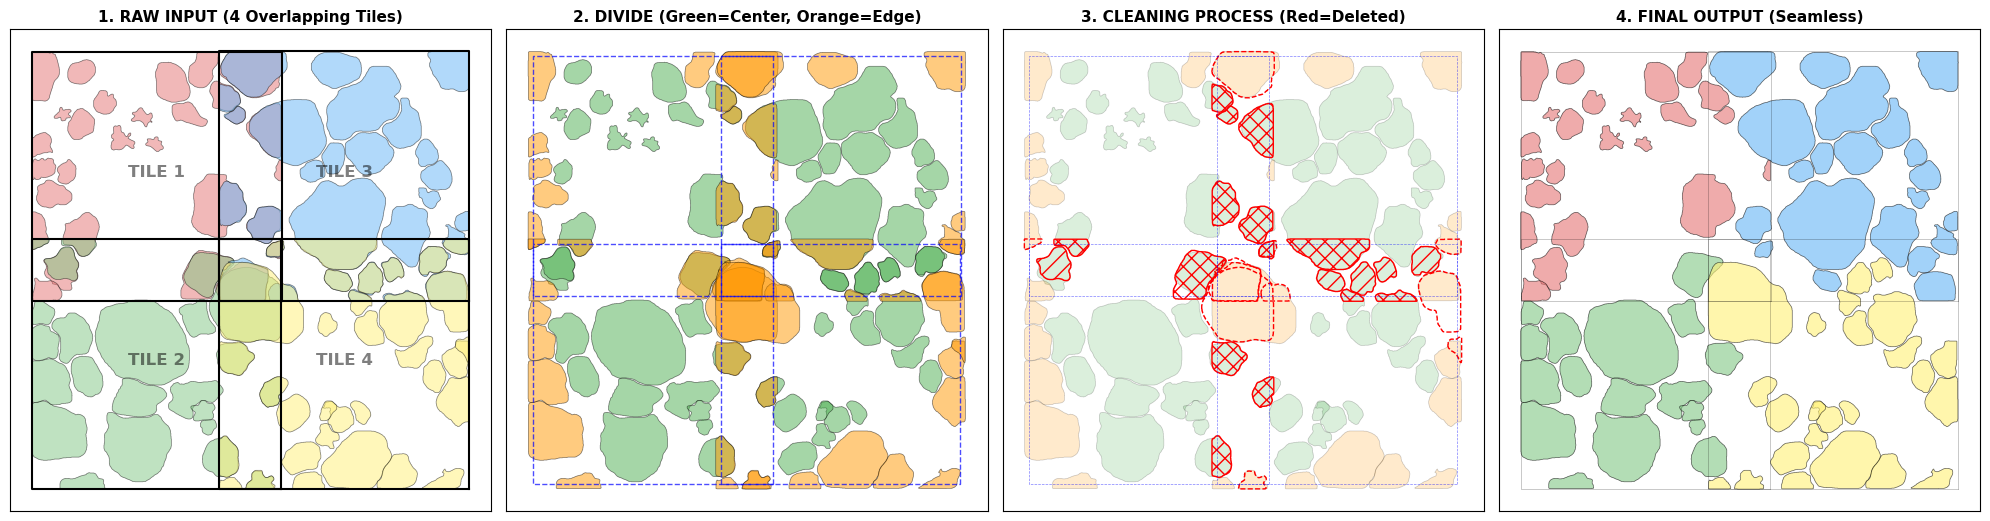

In [20]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from shapely.geometry import box
import os

# =============================================================================
# 1. PENGATURAN & PARAMETER
# =============================================================================
BASE_DIR = "D:/RESEARCH/SK2_ITCD_CHM/dataset/cmh01_02/tiles/geojson"
LIST_FILES = [
    os.path.join(BASE_DIR, "tile_4_5.geojson"),
    os.path.join(BASE_DIR, "tile_4_6.geojson"),
    os.path.join(BASE_DIR, "tile_5_5.geojson"),
    os.path.join(BASE_DIR, "tile_5_6.geojson")
]

SHIFT = 1.0
SCORE_COLUMN = "Confidence_score" 
OVERLAP_THRESHOLD = 0.5      # Threshold untuk NMS (IoMin) antar poligon sejenis
CROSS_ZONE_THRESHOLD = 0.15  # Toleransi 15% Edge termakan Center

# =============================================================================
# 2. FUNGSI LOGIKA (TERBARU: IoMin & Berbasis Skor)
# =============================================================================
def preprocess_tile(gdf):
    gdf["geometry"] = gdf.geometry.buffer(0)
    gdf = gdf[gdf.geometry.is_valid & ~gdf.geometry.is_empty]
    gdf = gdf[gdf.geometry.area >= 2.0]
    return gdf

def separate_kept_dropped_by_score(gdf, score_col, overlap_thresh):
    """NMS menggunakan IoMin, mereturn poligon yang dipertahankan dan yang dibuang."""
    if gdf.empty: return gdf, gdf.iloc[0:0]
    
    if score_col in gdf.columns:
        gdf = gdf.sort_values(by=score_col, ascending=False).reset_index(drop=True)
    else:
        gdf = gdf.reset_index(drop=True)

    sindex = gdf.sindex
    suppressed_indices = set()
    keep_indices = []

    for i, row in gdf.iterrows():
        if i in suppressed_indices: continue
            
        keep_indices.append(i)
        geom_A = row.geometry
        area_A = geom_A.area
        
        possible_matches = list(sindex.query(geom_A, predicate='intersects'))
        for j in possible_matches:
            if j <= i or j in suppressed_indices: continue
            
            geom_B = gdf.loc[j].geometry
            area_B = geom_B.area
            
            intersection_area = geom_A.intersection(geom_B).area
            if intersection_area == 0: continue
            
            # Logika IoMin
            min_area = min(area_A, area_B)
            if (intersection_area / min_area) > overlap_thresh:
                suppressed_indices.add(j)

    gdf_kept = gdf.loc[keep_indices].copy()
    gdf_dropped = gdf.loc[list(suppressed_indices)].copy()
    return gdf_kept, gdf_dropped

def apply_cross_zone_filter_viz(edge_gdf, center_master, threshold):
    """Menghapus Edge jika termakan Center > threshold. Mereturn kept & dropped."""
    if edge_gdf.empty or center_master.empty: return edge_gdf, edge_gdf.iloc[0:0]
    
    indices_to_delete = set()
    joined = gpd.sjoin(edge_gdf, center_master, how="inner", predicate="intersects")
    
    for edge_idx, row in joined.iterrows():
        if edge_idx in indices_to_delete: continue
        center_idx = row['index_right']
        
        try:
            edge_geom = edge_gdf.geometry.loc[edge_idx]
            center_geom = center_master.geometry.loc[center_idx]
            
            inter = edge_geom.intersection(center_geom).area
            if inter > 0 and (inter / edge_geom.area) > threshold:
                indices_to_delete.add(edge_idx)
        except: pass

    gdf_kept = edge_gdf.drop(index=list(indices_to_delete)).copy()
    gdf_dropped = edge_gdf.loc[list(indices_to_delete)].copy()
    return gdf_kept, gdf_dropped

# =============================================================================
# 3. PROSES VISUALISASI 4 TILE
# =============================================================================
def visualize_4_tiles_merge(file_list):
    print("Memproses visualisasi penggabungan 4 Tile...")
    
    all_centers = []
    all_edges = []
    tile_boundaries = []
    safe_boxes = []
    raw_tiles = []
    
    # --- TAHAP 1: BACA, PRAPROSES & DIVIDE ---
    print("  [Stage 1] Membaca & Memisahkan Center/Edge per Tile...")
    for i, fpath in enumerate(file_list):
        if not os.path.exists(fpath): 
            print(f"SKIP: {fpath} not found")
            continue
        
        gdf = gpd.read_file(fpath)
        gdf = preprocess_tile(gdf) # <-- Praproses ditambahkan
        if gdf.empty: continue
            
        gdf['tile_id'] = i + 1 
        raw_tiles.append(gdf)
        
        bounds = gdf.total_bounds
        safe_box = box(bounds[0]+SHIFT, bounds[1]+SHIFT, bounds[2]-SHIFT, bounds[3]-SHIFT)
        tile_box = box(bounds[0], bounds[1], bounds[2], bounds[3])
        
        safe_boxes.append(safe_box)
        tile_boundaries.append(tile_box)
        
        safe_box_gdf = gpd.GeoDataFrame(geometry=[safe_box], crs=gdf.crs)
        
        # Divide Center & Edge
        center_idxs = gpd.sjoin(gdf, safe_box_gdf, how="inner", predicate="within").index
        gdf_c = gdf.loc[center_idxs].copy()
        gdf_e = gdf.drop(index=center_idxs).copy()
        
        all_centers.append(gdf_c)
        all_edges.append(gdf_e)

    global_center = pd.concat(all_centers, ignore_index=True) if all_centers else gpd.GeoDataFrame()
    global_edge = pd.concat(all_edges, ignore_index=True) if all_edges else gpd.GeoDataFrame()
    
    # --- TAHAP 2: CLEANING (NMS) ---
    print("  [Stage 2] Global NMS (IoMin) Cleaning...")
    center_kept, center_drop = separate_kept_dropped_by_score(global_center, SCORE_COLUMN, OVERLAP_THRESHOLD)
    edge_kept, edge_drop = separate_kept_dropped_by_score(global_edge, SCORE_COLUMN, OVERLAP_THRESHOLD)
    
    # --- TAHAP 3: CROSS ZONE ---
    print("  [Stage 3] Cross-Zone Filter...")
    edge_final, edge_cross_drop = apply_cross_zone_filter_viz(edge_kept, center_kept, CROSS_ZONE_THRESHOLD)

    # ==========================
    # PLOTTING STORYBOARD
    # ==========================
    print("  [Plotting] Membuat Gambar...")
    fig, axes = plt.subplots(1, 4, figsize=(20, 5.5))
    colors = ['#e57373', '#81c784', '#64b5f6', '#fff176']
    
    # PANEL 1: RAW INPUT
    ax = axes[0]
    ax.set_title("1. RAW INPUT (4 Overlapping Tiles)", fontsize=11, fontweight='bold')
    for i, gdf in enumerate(raw_tiles):
        gdf.plot(ax=ax, color=colors[i % 4], alpha=0.5, edgecolor='black', linewidth=0.5)
        x, y = tile_boundaries[i].exterior.xy
        ax.plot(x, y, color='black', linestyle='-', linewidth=1.5)
        cx, cy = tile_boundaries[i].centroid.x, tile_boundaries[i].centroid.y
        ax.text(cx, cy, f"TILE {i+1}", fontsize=12, fontweight='bold', alpha=0.5, ha='center')

    # PANEL 2: DIVIDE
    ax = axes[1]
    ax.set_title("2. DIVIDE (Green=Center, Orange=Edge)", fontsize=11, fontweight='bold')
    if not global_center.empty:
        global_center.plot(ax=ax, color='#4caf50', alpha=0.5, edgecolor='black', linewidth=0.5)
    if not global_edge.empty:
        global_edge.plot(ax=ax, color='#ff9800', alpha=0.5, edgecolor='black', linewidth=0.5)
    for sb in safe_boxes:
        x, y = sb.exterior.xy
        ax.plot(x, y, color='blue', linestyle='--', linewidth=1, alpha=0.7)

    # PANEL 3: CLEANING
    ax = axes[2]
    ax.set_title("3. CLEANING PROCESS (Red=Deleted)", fontsize=11, fontweight='bold')
    if not center_kept.empty: center_kept.plot(ax=ax, color='#4caf50', alpha=0.2, edgecolor='black', linewidth=0.5)
    if not edge_final.empty: edge_final.plot(ax=ax, color='#ff9800', alpha=0.2, edgecolor='black', linewidth=0.5)
    
    # Plot sampah NMS Center (Arsir)
    if not center_drop.empty:
        center_drop.plot(ax=ax, facecolor='none', edgecolor='red', hatch='//', lw=1)
    # Plot sampah NMS Edge (Putus-putus)
    if not edge_drop.empty:
        edge_drop.plot(ax=ax, facecolor='none', edgecolor='red', linestyle='--', lw=1)
    # Plot sampah Cross-Zone (Silang)
    if not edge_cross_drop.empty:
        edge_cross_drop.plot(ax=ax, facecolor='none', edgecolor='red', hatch='xx', lw=1)
        
    for sb in safe_boxes:
        x, y = sb.exterior.xy
        ax.plot(x, y, color='blue', linestyle='--', linewidth=0.5, alpha=0.5)

    # PANEL 4: FINAL MERGED
    ax = axes[3]
    ax.set_title("4. FINAL OUTPUT (Seamless)", fontsize=11, fontweight='bold')
    final_gdf = pd.concat([center_kept, edge_final])
    
    for i in range(len(file_list)):
        tile_id = i + 1
        tile_data = final_gdf[final_gdf['tile_id'] == tile_id]
        if not tile_data.empty:
            tile_data.plot(ax=ax, color=colors[i % 4], alpha=0.6, edgecolor='black', linewidth=0.5)
            
    for tb in tile_boundaries:
         x, y = tb.exterior.xy
         ax.plot(x, y, color='black', linestyle='-', linewidth=0.5, alpha=0.3)

    for ax in axes:
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_aspect('equal')

    plt.tight_layout()
    plt.savefig("Visualisasi_DCGNMS_Final_v2.png", dpi=400)
    print("\n[SUKSES] Gambar 'Visualisasi_DCGNMS_Final.png' berhasil disimpan!")
    plt.show()

if __name__ == "__main__":
    visualize_4_tiles_merge(LIST_FILES)

Memproses visualisasi 3 Tahap Cleaning (Internal & Cross-Zone)...
  [Calculation] Membaca & Memisahkan Global Center/Edge...
  [Calculation] Internal Cleaning (IoMin NMS)...
  [Calculation] Cross-Zone Filter (IoA)...
  [Plotting] Membuat Gambar 3 Panel...

[SUKSES] Gambar 'Visualisasi_Full_Cleaning_Stages.png' berhasil disimpan!


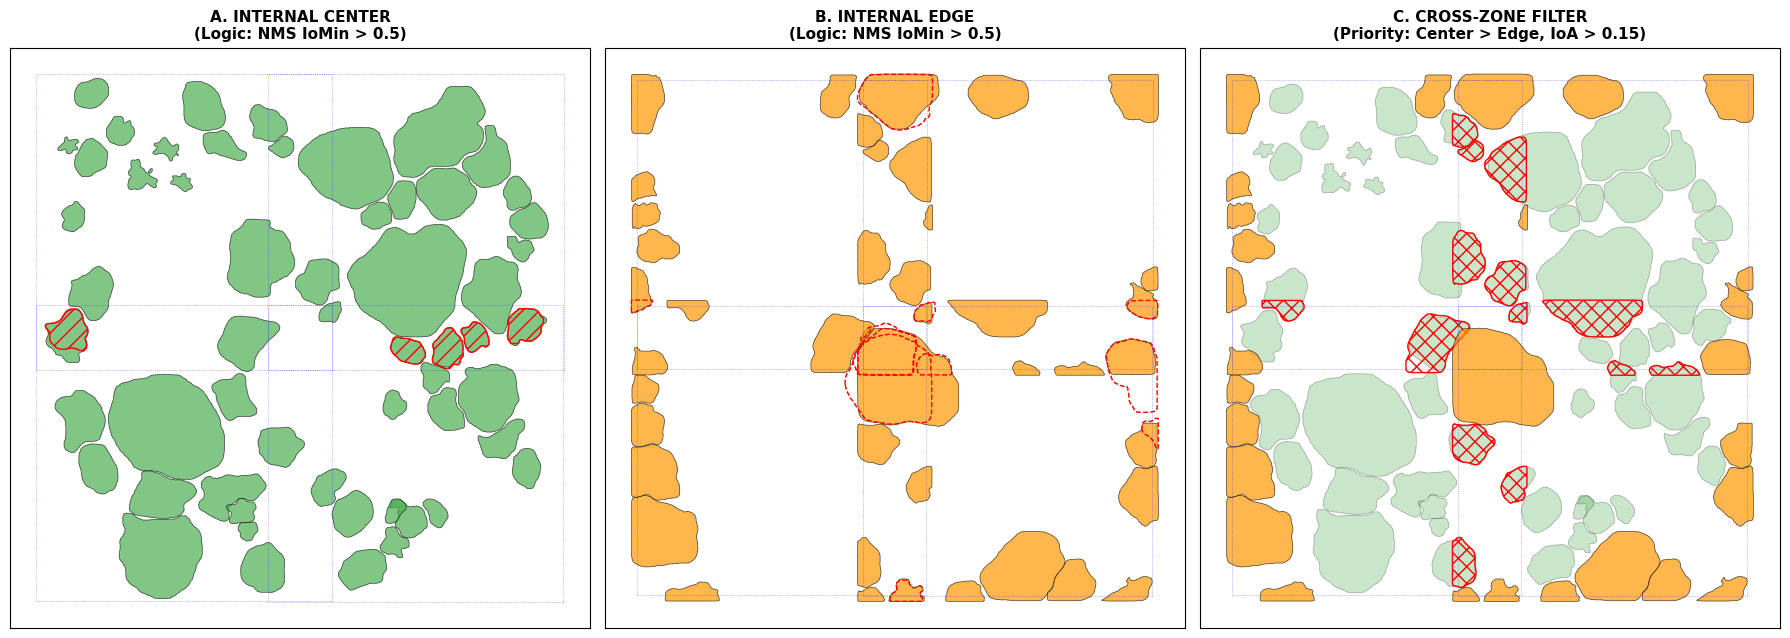

In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from shapely.geometry import box
import os

# =============================================================================
# 1. PENGATURAN & PARAMETER
# =============================================================================
BASE_DIR = "D:/RESEARCH/SK2_ITCD_CHM/dataset/cmh01_02/tiles/geojson"
LIST_FILES = [
    os.path.join(BASE_DIR, "tile_4_5.geojson"),
    os.path.join(BASE_DIR, "tile_4_6.geojson"),
    os.path.join(BASE_DIR, "tile_5_5.geojson"),
    os.path.join(BASE_DIR, "tile_5_6.geojson")
]

SHIFT = 1.0
SCORE_COLUMN = "Confidence_score" 
OVERLAP_THRESHOLD = 0.5      # Threshold NMS (IoMin) untuk Internal Center & Edge
CROSS_ZONE_THRESHOLD = 0.15  # Toleransi 15% Edge termakan Center

# =============================================================================
# 2. FUNGSI LOGIKA (NMS IoMin & Cross-Zone)
# =============================================================================
def preprocess_tile(gdf):
    gdf["geometry"] = gdf.geometry.buffer(0)
    gdf = gdf[gdf.geometry.is_valid & ~gdf.geometry.is_empty]
    gdf = gdf[gdf.geometry.area >= 2.0]
    return gdf

def separate_kept_dropped_by_score(gdf, score_col, overlap_thresh):
    """NMS menggunakan IoMin, memisahkan poligon survivor dan poligon artefak."""
    if gdf.empty: return gdf, gdf.iloc[0:0]
    
    if score_col in gdf.columns:
        gdf = gdf.sort_values(by=score_col, ascending=False).reset_index(drop=True)
    else:
        gdf = gdf.reset_index(drop=True)

    sindex = gdf.sindex
    suppressed_indices = set()
    keep_indices = []

    for i, row in gdf.iterrows():
        if i in suppressed_indices: continue
            
        keep_indices.append(i)
        geom_A = row.geometry
        area_A = geom_A.area
        
        possible_matches = list(sindex.query(geom_A, predicate='intersects'))
        for j in possible_matches:
            if j <= i or j in suppressed_indices: continue
            
            geom_B = gdf.loc[j].geometry
            area_B = geom_B.area
            
            intersection_area = geom_A.intersection(geom_B).area
            if intersection_area == 0: continue
            
            # IoMin: Area irisan dibagi area poligon terkecil
            min_area = min(area_A, area_B)
            if (intersection_area / min_area) > overlap_thresh:
                suppressed_indices.add(j)

    return gdf.loc[keep_indices].copy(), gdf.loc[list(suppressed_indices)].copy()

def apply_cross_zone_filter_viz(edge_gdf, center_master, threshold):
    """Filter Cross-Zone berbasis IoA, memisahkan Edge yang selamat dan terhapus."""
    if edge_gdf.empty or center_master.empty: return edge_gdf, edge_gdf.iloc[0:0]
    
    indices_to_delete = set()
    joined = gpd.sjoin(edge_gdf, center_master, how="inner", predicate="intersects")
    
    for edge_idx, row in joined.iterrows():
        if edge_idx in indices_to_delete: continue
        center_idx = row['index_right']
        
        try:
            edge_geom = edge_gdf.geometry.loc[edge_idx]
            center_geom = center_master.geometry.loc[center_idx]
            
            inter = edge_geom.intersection(center_geom).area
            if inter > 0 and (inter / edge_geom.area) > threshold:
                indices_to_delete.add(edge_idx)
        except: pass

    return edge_gdf.drop(index=list(indices_to_delete)).copy(), edge_gdf.loc[list(indices_to_delete)].copy()

# =============================================================================
# 3. PROSES VISUALISASI FOKUS CLEANING & FILTERING (3 STAGE)
# =============================================================================
def visualize_cleaning_stages(file_list):
    print("Memproses visualisasi 3 Tahap Cleaning (Internal & Cross-Zone)...")
    
    all_centers, all_edges, safe_boxes = [], [], []
    
    # --- TAHAP 1: BACA, PRAPROSES & DIVIDE ---
    print("  [Calculation] Membaca & Memisahkan Global Center/Edge...")
    for i, fpath in enumerate(file_list):
        if not os.path.exists(fpath): 
            print(f"SKIP: {fpath} not found")
            continue
            
        gdf = gpd.read_file(fpath)
        gdf = preprocess_tile(gdf) # Praproses topologi
        if gdf.empty: continue
            
        bounds = gdf.total_bounds
        safe_box = box(bounds[0]+SHIFT, bounds[1]+SHIFT, bounds[2]-SHIFT, bounds[3]-SHIFT)
        safe_boxes.append(safe_box)
        safe_box_gdf = gpd.GeoDataFrame(geometry=[safe_box], crs=gdf.crs)
        
        center_idxs = gpd.sjoin(gdf, safe_box_gdf, how="inner", predicate="within").index
        all_centers.append(gdf.loc[center_idxs].copy())
        all_edges.append(gdf.drop(index=center_idxs).copy())

    global_center = pd.concat(all_centers, ignore_index=True) if all_centers else gpd.GeoDataFrame()
    global_edge = pd.concat(all_edges, ignore_index=True) if all_edges else gpd.GeoDataFrame()
    
    # --- TAHAP 2: INTERNAL CLEANING ---
    print("  [Calculation] Internal Cleaning (IoMin NMS)...")
    center_kept, center_drop = separate_kept_dropped_by_score(global_center, SCORE_COLUMN, OVERLAP_THRESHOLD)
    edge_kept, edge_drop = separate_kept_dropped_by_score(global_edge, SCORE_COLUMN, OVERLAP_THRESHOLD)
    
    # --- TAHAP 3: CROSS ZONE FILTER ---
    print("  [Calculation] Cross-Zone Filter (IoA)...")
    edge_final, edge_cross_drop = apply_cross_zone_filter_viz(edge_kept, center_kept, CROSS_ZONE_THRESHOLD)


    # ==========================
    # PLOTTING 3 PANEL
    # ==========================
    print("  [Plotting] Membuat Gambar 3 Panel...")
    fig, axes = plt.subplots(1, 3, figsize=(18, 7))
    
    # --- PANEL A: INTERNAL CENTER ---
    ax1 = axes[0]
    ax1.set_title(f"A. INTERNAL CENTER\n(Logic: NMS IoMin > {OVERLAP_THRESHOLD})", fontsize=11, fontweight='bold')
    if not center_kept.empty:
        center_kept.plot(ax=ax1, color='#4caf50', alpha=0.7, edgecolor='black', linewidth=0.5)
    if not center_drop.empty:
        center_drop.plot(ax=ax1, facecolor='none', edgecolor='red', hatch='//', linewidth=1)
    
    # --- PANEL B: INTERNAL EDGE ---
    ax2 = axes[1]
    ax2.set_title(f"B. INTERNAL EDGE\n(Logic: NMS IoMin > {OVERLAP_THRESHOLD})", fontsize=11, fontweight='bold')    
    if not edge_kept.empty:
        edge_kept.plot(ax=ax2, color='#ff9800', alpha=0.7, edgecolor='black', linewidth=0.5)
    if not edge_drop.empty:
        edge_drop.plot(ax=ax2, facecolor='none', edgecolor='red', linestyle='--', linewidth=1)
        
    # --- PANEL C: CROSS-ZONE FILTER ---
    ax3 = axes[2]
    ax3.set_title(f"C. CROSS-ZONE FILTER\n(Priority: Center > Edge, IoA > {CROSS_ZONE_THRESHOLD})", fontsize=11, fontweight='bold')
    
    if not center_kept.empty:
        center_kept.plot(ax=ax3, color='#4caf50', alpha=0.3, edgecolor='black', linewidth=0.5)
    if not edge_cross_drop.empty:
        edge_cross_drop.plot(ax=ax3, facecolor='none', edgecolor='red', hatch='XX', linewidth=1.0)
    if not edge_final.empty:
        edge_final.plot(ax=ax3, color='#ff9800', alpha=0.7, edgecolor='black', linewidth=0.5)

    # --- FINALISASI PLOT & LEGENDA CUSTOM ---
    for ax in axes:
        ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect('equal')
        
        for sb in safe_boxes:
             x, y = sb.exterior.xy
             ax.plot(x, y, color='blue', linestyle=':', linewidth=0.5, alpha=0.5)
             
        # Custom Legend
        legend_elements = []
        if ax == axes[0]:
            legend_elements = [
                patches.Patch(color='#4caf50', alpha=0.7, label='Kept Center'),
                patches.Patch(facecolor='none', edgecolor='red', hatch='//', label='NMS Duplicate (Removed)')
            ]
        elif ax == axes[1]:
            legend_elements = [
                patches.Patch(color='#ff9800', alpha=0.7, label='Kept Edge'),
                patches.Patch(facecolor='none', edgecolor='red', linestyle='--', label='NMS Fragment (Removed)')
            ]
        elif ax == axes[2]:
            legend_elements = [
                patches.Patch(color='#4caf50', alpha=0.3, label='Context Center'),
                patches.Patch(color='#ff9800', alpha=0.7, ec='black', label='Final Edge (Survivor)'),
                patches.Patch(facecolor='none', edgecolor='red', hatch='XX', label=f'Overlap > {CROSS_ZONE_THRESHOLD*100}% w/ Center')
            ]
        # ax.legend(handles=legend_elements, loc='lower center', ncol=1 if ax != axes[2] else 1, fontsize=9)

    plt.tight_layout()
    output_filename = "Visualisasi_Full_Cleaning_Stages.png"
    plt.savefig(output_filename, dpi=400)
    print(f"\n[SUKSES] Gambar '{output_filename}' berhasil disimpan!")
    plt.show()

if __name__ == "__main__":
    visualize_cleaning_stages(LIST_FILES)

# NMS Standar (Ball et al.)

In [4]:
import os
import glob
import rasterio
import pandas as pd
import geopandas as gpd
from shapely.geometry import box

def calc_iou(shape1, shape2):
    """Menghitung persentase tumpang tindih (IoU) dari dua poligon."""
    intersection_area = shape1.intersection(shape2).area
    union_area = shape1.union(shape2).area
    return intersection_area / union_area if union_area > 0 else 0

def clean_crowns(crowns: gpd.GeoDataFrame,
                 iou_threshold: float = 0.5,
                 confidence_threshold: float = 0.5,
                 area_threshold: float = 2.0,
                 field: str = "Confidence_score") -> gpd.GeoDataFrame:
    """Membersihkan poligon tumpang tindih (NMS) dengan IoU tertentu."""
    
    # Filter yang tidak valid dan ukurannya terlalu kecil (artefak)
    crowns = crowns[~crowns.is_empty & crowns.is_valid]
    crowns = crowns[crowns.area > area_threshold]
    crowns.reset_index(drop=True, inplace=True)

    cleaned_crowns = []
    print(f"Memulai pembersihan {len(crowns)} poligon...")

    for index, row in crowns.iterrows():
        if index % 1000 == 0 and index > 0:
            print(f"  Memproses {index} / {len(crowns)} poligon...")

        intersecting_rows = crowns[crowns.intersects(row.geometry)]

        if len(intersecting_rows) > 1:
            iou_values = intersecting_rows.geometry.apply(lambda x: calc_iou(row.geometry, x))
            intersecting_rows = intersecting_rows.assign(iou=iou_values)

            # Ambil 1 poligon dengan score tertinggi di antara yang overlap
            match = intersecting_rows[intersecting_rows["iou"] > iou_threshold].nlargest(1, field)

            if len(match) > 0 and match["iou"].iloc[0] < 1:
                continue
        else:
            match = row.to_frame().T

        cleaned_crowns.append(match)

    if cleaned_crowns:
        crowns_out = pd.concat(cleaned_crowns, ignore_index=True)
        if "iou" in crowns_out.columns:
            crowns_out = crowns_out.drop("iou", axis=1)
    else:
        crowns_out = gpd.GeoDataFrame()

    if not isinstance(crowns_out, gpd.GeoDataFrame):
        crowns_out = gpd.GeoDataFrame(crowns_out, crs=crowns.crs)
    else:
        crowns_out = crowns_out.set_crs(crowns.crs, allow_override=True)

    # Filter skor akhir
    if confidence_threshold > 0 and field in crowns_out.columns:
        crowns_out[field] = pd.to_numeric(crowns_out[field])
        crowns_out = crowns_out[crowns_out[field] >= confidence_threshold]

    return crowns_out.reset_index(drop=True)

def filter_edge_crowns(gdf_tile, tif_path, shift=1.0):
    """
    MEMBUAT MEKANISME SHIFT 1 METER MILIK BALL:
    Membaca batas tepi (bounding box) dari file .tif asli, mengecilkannya 
    sejauh `shift` meter, dan membuang semua pohon yang menyentuh/melewati batas tersebut.
    """
    with rasterio.open(tif_path) as src:
        # Ambil batas luar gambar .tif dalam satuan meter (CRS geospasial)
        minx, miny, maxx, maxy = src.bounds.left, src.bounds.bottom, src.bounds.right, src.bounds.top
        
    # Buat kotak (bounding box) dan kecilkan sebanyak 'shift' (default: 1 meter)
    shrunken_bbox = box(minx + shift, miny + shift, maxx - shift, maxy - shift)
    
    # Hanya simpan poligon pohon yang SEPENUHNYA BERADA DI DALAM kotak yang sudah dikecilkan
    gdf_filtered = gdf_tile[gdf_tile.geometry.within(shrunken_bbox)]
    
    return gdf_filtered

def stitch_and_clean_pipeline(geojson_dir: str, tif_dir: str, output_gpkg: str, shift: float = 1.0):
    geojson_files = glob.glob(os.path.join(geojson_dir, "*.geojson"))
    
    if not geojson_files:
        print(f"[!] Tidak ada file GeoJSON di {geojson_dir}")
        return

    print(f"Tahap 1: Stitching & Edge Bounding Box Shift ({shift}m) pada {len(geojson_files)} file...")
    
    gdfs = []
    for geojson_file in geojson_files:
        gdf = gpd.read_file(geojson_file)
        if gdf.empty:
            continue
            
        # Cari file .tif pasangannya (misal: tile_0_0.geojson -> tile_0_0.tif)
        base_name = os.path.splitext(os.path.basename(geojson_file))[0]
        tif_path = os.path.join(tif_dir, f"{base_name}.tif")
        
        if not os.path.exists(tif_path):
            print(f"  [!] Peringatan: File {base_name}.tif tidak ditemukan. Shift dilewati untuk file ini.")
            gdfs.append(gdf)
            continue
            
        # Terapkan mekanisme potong tepi 1 meter
        gdf_shifted = filter_edge_crowns(gdf, tif_path, shift=shift)
        gdfs.append(gdf_shifted)
        
    # Gabungkan (Stitch) semua tile yang sudah dipotong tepinya
    merged_gdf = pd.concat(gdfs, ignore_index=True)
    merged_gdf = gpd.GeoDataFrame(merged_gdf, crs=gdfs[0].crs)
    print(f"Total poligon setelah Stitching + Shift tepi: {len(merged_gdf)}")
    
    # Tahap 2: Proses pembersihan (NMS & Score Thresholding)
    print("\nTahap 2: Cleaning (NMS) & Filtering...")
    
    # Menjalankan pembersihan persis seperti urutan instruksi Anda
    cleaned_gdf = clean_crowns(
        crowns=merged_gdf, 
        iou_threshold=0.5,         # Sesuai langkah Anda
        confidence_threshold=0.5,  # Sesuai langkah Anda
        field="Confidence_score"   # Sesuaikan field score dari geojson Anda
    )
    
    print(f"Total poligon akhir (Siap ekspor): {len(cleaned_gdf)}")
    
    # Tahap 3: Simpan ke GPKG
    cleaned_gdf.to_file(output_gpkg, driver="GPKG")
    print(f"\n[v] Selesai! File bersih tersimpan di: {output_gpkg}")

In [5]:
# =======================================================
# CARA PENGGUNAAN
# =======================================================
SITE_PATH = "./sample/tiles/"

DIR_PREDICTIONS = os.path.join(SITE_PATH, "geojson") 
DIR_TILES_TIF   = os.path.join(SITE_PATH, "") # Folder tempat tile_0_0.tif berada
FILE_OUTPUT     = os.path.join(SITE_PATH, "tree_crowns_ball.gpkg")

# Jalankan pipeline penuh:
stitch_and_clean_pipeline(
    geojson_dir = DIR_PREDICTIONS, 
    tif_dir     = DIR_TILES_TIF, 
    output_gpkg = FILE_OUTPUT,
    shift       = 1.0  # Pemotongan tepi (margin pinggir gambar) sejauh 1 meter
)

Tahap 1: Stitching & Edge Bounding Box Shift (1.0m) pada 167 file...
Total poligon setelah Stitching + Shift tepi: 1805

Tahap 2: Cleaning (NMS) & Filtering...
Memulai pembersihan 1719 poligon...
  Memproses 1000 / 1719 poligon...
Total poligon akhir (Siap ekspor): 1391

[v] Selesai! File bersih tersimpan di: ./sample/tiles/tree_crowns_ball.gpkg
